In [ ]:
# Install specific version of timm for stable ConvNeXt implementation
!pip -q install timm==1.0.9

# Standard library imports for file handling, numeric operations, logging, etc.
import os, time, math, random, json, shutil, gc, warnings
from pathlib import Path

# Numerical and data utilities
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from collections import Counter

# PyTorch imports for model building and training
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms
from PIL import Image, ImageFile

# Vision model library
import timm

# Evaluation metrics
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Disable warnings for clean output
warnings.filterwarnings('ignore')
ImageFile.LOAD_TRUNCATED_IMAGES = True
os.environ['PYTHONWARNINGS'] = 'ignore'

# Set seeds to make training reproducible
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Enable optimized GPU performance
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.deterministic = False


# Detect dataset root folder automatically
def find_data_root():
    # List of likely dataset locations
    candidates = [
        Path("/kaggle/input/fffdsas/malayalam_data"),
        Path("/kaggle/input/fffdsas/malayalam_data.zip"),
    ]

    # Search recursively for .zip file named malayalam_data
    for z in Path("/kaggle/input/fffdsas").glob("**/malayalam_data.zip"):
        candidates.append(z)

    # Search recursively for extracted malayalam_data folder
    for d in Path("/kaggle/input/fffdsas").glob("**/malayalam_data"):
        candidates.append(d)

    # Select the first valid path
    for p in candidates:
        if p.exists():
            return p

    # Final fallback: check subdirectories for the folder
    for root in Path("/kaggle/input/fffdsas").glob("*"):
        if (root / "malayalam_data").exists():
            return root / "malayalam_data"

    return None


# Get dataset root path
DATA_ROOT = find_data_root()
assert DATA_ROOT is not None, "Dataset not found!"
print(f"Detected DATA_ROOT: {DATA_ROOT}")

# If the dataset is a zip file, extract it
if DATA_ROOT.suffix.lower() == ".zip":
    out_dir = Path("/kaggle/working/malayalam_data_unzipped")
    if not (out_dir.exists() and any(out_dir.iterdir())):
        print(f"Unzipping {DATA_ROOT} to {out_dir}")
        shutil.unpack_archive(str(DATA_ROOT), str(out_dir))
    DATA_ROOT = out_dir


# Standardize dataset folder structure.
# Some datasets are nested inside an additional directory.
# This function repeatedly unwraps single-folder structures until train/all directories appear.
def canonicalize_data_root(dr: Path) -> Path:
    tries = 0
    while tries < 3:
        train_here = (dr / "train").exists()
        all_here = (dr / "all").exists()

        # If there is only one folder and no "train" or "all", move into it
        subdirs = [d for d in dr.iterdir() if d.is_dir()]
        if (not train_here and not all_here) and len(subdirs) == 1:
            dr = subdirs[0]
        else:
            break

        tries += 1

    return dr


# Build train/val/test split from a single "all" directory
# train 75%, val 15%, test 10%
def build_tvt_from_all(all_dir: Path, train_ratio=0.75, val_ratio=0.15):
    tmp_root = Path("/kaggle/working/malayalam_data_split")

    # Remove old split if it exists
    if tmp_root.exists():
        shutil.rmtree(tmp_root)

    # Create folders for new split
    (tmp_root / "train").mkdir(parents=True, exist_ok=True)
    (tmp_root / "val").mkdir(parents=True, exist_ok=True)
    (tmp_root / "test").mkdir(parents=True, exist_ok=True)

    # Detect class folders
    classes = sorted([d.name for d in all_dir.iterdir() if d.is_dir()])

    # Valid image extensions
    exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

    # For each class, shuffle and split files
    for c in classes:
        src = all_dir / c
        imgs = [p for p in sorted(src.rglob("*")) if p.is_file() and p.suffix.lower() in exts]

        if len(imgs) == 0:
            continue

        random.shuffle(imgs)

        n = len(imgs)
        n_train = int(n * train_ratio)
        n_val = int(n * val_ratio)

        # Define the splits
        splits = {
            "train": imgs[:n_train],
            "val": imgs[n_train:n_train + n_val],
            "test": imgs[n_train + n_val:]
        }

        # Create output folders and copy or link images
        for split, paths in splits.items():
            out = tmp_root / split / c
            out.mkdir(parents=True, exist_ok=True)

            for p in paths:
                try:
                    os.link(p, out / p.name)  # Hard link if possible
                except Exception:
                    shutil.copy2(p, out / p.name)  # Fallback to copy

    return tmp_root


# Normalize dataset structure
DATA_ROOT = canonicalize_data_root(DATA_ROOT)

# Check if dataset already contains train/val folders
HAS_TVT = (DATA_ROOT / "train").exists() and (DATA_ROOT / "val").exists()
HAS_ALL = (DATA_ROOT / "all").exists()

# If no structured split is found, attempt to split automatically
if not HAS_TVT and not HAS_ALL:
    class_dirs = [d for d in DATA_ROOT.iterdir() if d.is_dir() and any(d.iterdir())]

    # If there are multiple class folders, assume a flat dataset and split it
    if len(class_dirs) >= 2:
        print("Creating train/val/test splits (75/15/10)")
        DATA_ROOT = build_tvt_from_all(DATA_ROOT)
        HAS_TVT = True

# Ensure train and val exist
assert (DATA_ROOT / "train").exists() and (DATA_ROOT / "val").exists()


# Class that applies Mixup or CutMix randomly during training.
# Adds regularization and improves generalization when dataset is limited.
class MixupCutmix:
    def __init__(self, mixup_alpha=0.2, cutmix_alpha=1.0, prob=0.5, num_classes=10):
        self.mixup_alpha = mixup_alpha
        self.cutmix_alpha = cutmix_alpha
        self.prob = prob
        self.num_classes = num_classes

    # Decide whether to apply either augmentation for a given batch
    def __call__(self, x, y):
        if np.random.rand() > self.prob:
            return x, y

        # Randomly choose between Mixup and CutMix
        if np.random.rand() > 0.5:
            return self.mixup(x, y)
        else:
            return self.cutmix(x, y)

    # Mixup creates a weighted blend of two images and their labels
    def mixup(self, x, y):
        lam = np.random.beta(self.mixup_alpha, self.mixup_alpha)
        batch_size = x.size(0)

        # Randomly shuffle batch indices
        index = torch.randperm(batch_size, device=x.device)

        # Blend the images
        mixed_x = lam * x + (1 - lam) * x[index]

        # Convert labels to one-hot for blending
        y_onehot = F.one_hot(y, self.num_classes).float()
        mixed_y = lam * y_onehot + (1 - lam) * y_onehot[index]

        return mixed_x, mixed_y

    # CutMix replaces a random patch of an image with a patch from another image
    def cutmix(self, x, y):
        lam = np.random.beta(self.cutmix_alpha, self.cutmix_alpha)
        batch_size = x.size(0)

        index = torch.randperm(batch_size, device=x.device)

        # Get bounding box region for replacement
        bbx1, bby1, bbx2, bby2 = self.rand_bbox(x.size(), lam)

        # Replace part of the image
        x[:, :, bbx1:bbx2, bby1:bby2] = x[index, :, bbx1:bbx2, bby1:bby2]

        # Adjust lambda based on patch area
        lam = 1 - ((bbx2 - bbx1) * (bby2 - bby1) / (x.size(-1) * x.size(-2)))

        # Blend labels
        y_onehot = F.one_hot(y, self.num_classes).float()
        mixed_y = lam * y_onehot + (1 - lam) * y_onehot[index]

        return x, mixed_y

    # Create random bounding box for CutMix
    def rand_bbox(self, size, lam):
        W, H = size[2], size[3]

        # CutMix ratio based on lambda
        cut_rat = np.sqrt(1. - lam)
        cut_w = int(W * cut_rat)
        cut_h = int(H * cut_rat)

        # Random center point
        cx = np.random.randint(W)
        cy = np.random.randint(H)

        # Clip box within image bounds
        bbx1 = np.clip(cx - cut_w // 2, 0, W)
        bby1 = np.clip(cy - cut_h // 2, 0, H)
        bbx2 = np.clip(cx + cut_w // 2, 0, W)
        bby2 = np.clip(cy + cut_h // 2, 0, H)

        return bbx1, bby1, bbx2, bby2
# Set the input image size for training and evaluation
IMG_SIZE = 224

# Define augmentation pipeline for training images.
# Training augmentation includes geometric distortions, color changes, blurring,
# flips, random erasing, and normalization.
train_tfms = transforms.Compose([
    # Resize all images to the same resolution
    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    # Randomly choose between affine transformation or perspective distortion
    transforms.RandomChoice([
        transforms.RandomAffine(
            degrees=10,
            translate=(0.1, 0.1),
            scale=(0.9, 1.1),
            shear=7
        ),
        transforms.RandomPerspective(
            distortion_scale=0.2,
            p=0.5
        ),
    ]),

    # Random color changes applied with 50 percent probability
    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.15,
            hue=0.05
        )
    ], p=0.5),

    # Random blur applied occasionally
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.5))
    ], p=0.25),

    # Random horizontal flip
    transforms.RandomHorizontalFlip(p=0.3),

    # Convert image to tensor
    transforms.ToTensor(),

    # Randomly erase small regions to improve robustness
    transforms.RandomErasing(
        p=0.25,
        scale=(0.02, 0.2),
        ratio=(0.3, 3.3)
    ),

    # Normalize RGB channels
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# Validation and testing transformations do not include random augmentation.
# Only resizing and normalization are applied.
val_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])
# Identify the folder paths for train, validation, and test sets
train_dir = DATA_ROOT / "train"
val_dir = DATA_ROOT / "val"
test_dir = (DATA_ROOT / "test") if (DATA_ROOT / "test").exists() else (DATA_ROOT / "val")

# Load the datasets using ImageFolder, applying the corresponding transforms
train_ds = datasets.ImageFolder(train_dir, transform=train_tfms)
val_ds = datasets.ImageFolder(val_dir, transform=val_tfms)
test_ds = datasets.ImageFolder(test_dir, transform=val_tfms)

# Extract class names and number of classes
CLASSES = train_ds.classes
NUM_CLASSES = len(CLASSES)

print(f"\nDataset: Malayalam Characters")
print(f"Classes: {NUM_CLASSES}")
print(f"Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}\n")

# Count number of samples per class for imbalance detection
train_counts = Counter([label for _, label in train_ds.samples])
val_counts = Counter([label for _, label in val_ds.samples])

print(
    f"Samples per class: min={min(train_counts.values())}, "
    f"max={max(train_counts.values())}, "
    f"avg={len(train_ds)//NUM_CLASSES:.1f}"
)
# Determine whether weighted sampling is needed.
# If the largest class is more than twice the size of the smallest, use it.
USE_WEIGHTED_SAMPLING = max(train_counts.values()) / min(train_counts.values()) > 2.0

if USE_WEIGHTED_SAMPLING:
    print("Detected class imbalance. Using WeightedRandomSampler")

    # Compute weight for each class based on inverse frequency
    class_weights = {
        cls: len(train_ds) / count
        for cls, count in train_counts.items()
    }

    # Assign weight to each sample
    sample_weights = [class_weights[label] for _, label in train_ds.samples]

    # Create sampler to oversample rare classes
    sampler = WeightedRandomSampler(
        sample_weights,
        len(train_ds),
        replacement=True
    )
    shuffle_train = False
else:
    sampler = None
    shuffle_train = True
    # Training configuration
BATCH_SIZE = 48
NUM_WORKERS = 0
EPOCHS = 60
BASE_LR = 2.5e-5
MIN_LR = 5e-7
WEIGHT_DECAY = 1.5e-3
DROP_RATE = 0.35
DROP_PATH = 0.35
LABEL_SMOOTH = 0.2
WARMUP_EPOCHS = 3

# Choose GPU if available
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}\n")

# Create DataLoaders for training, validation, and testing
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    shuffle=shuffle_train,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)
# Create ConvNeXt Tiny model with pretrained weights
# The final classification head is replaced to match the number of classes
model = timm.create_model(
    "convnext_tiny",
    pretrained=True,
    num_classes=NUM_CLASSES,
    drop_rate=DROP_RATE,
    drop_path_rate=DROP_PATH
)

# Move model to GPU or CPU
model.to(DEVICE)

print(
    f"Model: convnext_tiny | Params: "
    f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M\n"
)
# Create Mixup+CutMix augmentation handler
mixup_cutmix = MixupCutmix(
    mixup_alpha=0.2,
    cutmix_alpha=1.0,
    prob=0.6,
    num_classes=NUM_CLASSES
)

# Loss function with label smoothing to improve stability
criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

# AdamW optimizer with weight decay
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=BASE_LR,
    weight_decay=WEIGHT_DECAY
)

# Cosine learning rate schedule with warm restarts
scheduler = CosineAnnealingWarmRestarts(
    optimizer,
    T_0=10,
    T_mult=2,
    eta_min=MIN_LR
)

# Enable mixed-precision training on GPU to improve speed
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))
# Compute accuracy from model logits.
# If Mixup/CutMix was applied, targets will be one-hot vectors.
def accuracy_from_logits(logits, targets):
    if targets.dim() > 1:
        targets = targets.argmax(dim=1)

    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()
# Run one epoch of training or validation.
def run_epoch(loader, train=True):
    model.train(train)

    epoch_loss, epoch_acc = 0.0, 0.0
    n_items = 0

    pbar = tqdm(loader, leave=False, desc=("Train" if train else "Val"))

    for imgs, y in pbar:
        imgs = imgs.to(DEVICE, non_blocking=True)
        y = y.to(DEVICE, non_blocking=True)

        # Apply Mixup or CutMix during training only
        if train:
            imgs, y = mixup_cutmix(imgs, y)

        # Forward pass with mixed-precision
        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(imgs)

            # If labels are one-hot (Mixup/CutMix), compute soft cross entropy
            if y.dim() > 1:
                loss = -(y * F.log_softmax(logits, dim=1)).sum(dim=1).mean()
            else:
                loss = criterion(logits, y)

        # Backpropagation during training
        if train:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
            scaler.step(optimizer)
            scaler.update()

        # Compute accuracy for display
        acc = accuracy_from_logits(logits, y)
        bs = imgs.size(0)

        epoch_loss += loss.item() * bs
        epoch_acc += acc * bs
        n_items += bs

        pbar.set_postfix({"loss": f"{loss.item():.3f}", "acc": f"{acc * 100:.1f}%"})

    return epoch_loss / n_items, epoch_acc / n_items
@torch.no_grad()
def evaluate(loader):
    model.eval()

    total_loss, total_acc, n_items = 0.0, 0.0, 0

    for imgs, y in loader:
        imgs = imgs.to(DEVICE)
        y = y.to(DEVICE)

        with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
            logits = model(imgs)
            loss = criterion(logits, y)

        acc = accuracy_from_logits(logits, y)
        bs = imgs.size(0)

        total_loss += loss.item() * bs
        total_acc += acc * bs
        n_items += bs

    return total_loss / n_items, total_acc / n_items
best_val_acc = -1.0
best_path = Path("/kaggle/working/best_model.pth")

# For early stopping
patience = 10
patience_counter = 0

print("Training started\n")

for epoch in range(1, EPOCHS + 1):

    # Linear warmup for the first few epochs
    if epoch <= WARMUP_EPOCHS:
        for pg in optimizer.param_groups:
            pg["lr"] = BASE_LR * epoch / WARMUP_EPOCHS

    t0 = time.time()

    # Train and validate
    train_loss, train_acc = run_epoch(train_loader, train=True)
    val_loss, val_acc = evaluate(val_loader)

    # Update learning rate after warmup
    if epoch > WARMUP_EPOCHS:
        scheduler.step()

    elapsed = time.time() - t0
    lr = optimizer.param_groups[0]["lr"]

    print(
        f"[{epoch:02d}/{EPOCHS}] "
        f"Train: {train_loss:.3f}/{train_acc * 100:.2f}% | "
        f"Val: {val_loss:.3f}/{val_acc * 100:.2f}% | "
        f"LR: {lr:.2e} | {elapsed:.1f}s",
        end=""
    )

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        patience_counter = 0

        torch.save(
            {
                "model": model.state_dict(),
                "val_acc": best_val_acc,
                "epoch": epoch,
                "classes": CLASSES
            },
            best_path
        )

        print(" [BEST]")

    else:
        patience_counter += 1
        print()

        # If no improvement for many epochs, stop training early
        if patience_counter >= patience:
            print(f"\nEarly stopping at epoch {epoch}")
            break
@torch.no_grad()
def predict_with_tta(loader, n_tta=5):
    model.eval()

    # Define several deterministic augmentations to average predictions
    tta_tfms = [
        val_tfms,
        transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomHorizontalFlip(p=1.0),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3),
        ]),
        transforms.Compose([
            transforms.Resize((240, 240)),
            transforms.CenterCrop(IMG_SIZE),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3),
        ]),
        transforms.Compose([
            transforms.Resize((IMG_SIZE, IMG_SIZE)),
            transforms.RandomRotation(5),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3),
        ]),
        transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.CenterCrop(IMG_SIZE),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3),
        ]),
    ][:n_tta]

    all_preds, all_labels = [], []

    for img_path, label in tqdm(loader.dataset.samples, desc="TTA", leave=False):
        img = Image.open(img_path).convert("RGB")

        batch_logits = []

        # Run several augmented versions of each image
        for tfm in tta_tfms:
            img_t = tfm(img).unsqueeze(0).to(DEVICE)

            with torch.amp.autocast("cuda", enabled=(DEVICE.type == "cuda")):
                logits = model(img_t)

            batch_logits.append(logits.cpu())

        # Average predictions from multiple versions
        avg_logits = torch.stack(batch_logits).mean(dim=0)

        pred = avg_logits.argmax(dim=1).item()

        all_preds.append(pred)
        all_labels.append(label)

    return np.array(all_preds), np.array(all_labels)
ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["model"])

print(
    f"\nLoaded best model from epoch {ckpt['epoch']} "
    f"(Val Acc: {ckpt['val_acc'] * 100:.2f}%)\n"
)

# Evaluate on the test dataset without TTA
test_loss, test_acc = evaluate(test_loader)
print(f"Test Acc (standard): {test_acc * 100:.2f}%")

# Evaluate using Test-Time Augmentation
print("Running Test-Time Augmentation (5x)")
tta_preds, tta_labels = predict_with_tta(test_loader, n_tta=5)
tta_acc = accuracy_score(tta_labels, tta_preds)

print(f"Test Acc (with TTA): {tta_acc * 100:.2f}%")
ckpt = torch.load(best_path, map_location=DEVICE)
model.load_state_dict(ckpt["model"])

print(
    f"\nLoaded best model from epoch {ckpt['epoch']} "
    f"(Val Acc: {ckpt['val_acc'] * 100:.2f}%)\n"
)

# Evaluate on the test dataset without TTA
test_loss, test_acc = evaluate(test_loader)
print(f"Test Acc (standard): {test_acc * 100:.2f}%")

# Evaluate using Test-Time Augmentation
print("Running Test-Time Augmentation (5x)")
tta_preds, tta_labels = predict_with_tta(test_loader, n_tta=5)
tta_acc = accuracy_score(tta_labels, tta_preds)

print(f"Test Acc (with TTA): {tta_acc * 100:.2f}%")
results = {
    "best_val_acc": float(best_val_acc),
    "test_acc": float(test_acc),
    "test_acc_tta": float(tta_acc),
    "num_classes": NUM_CLASSES,
    "epochs_trained": ckpt["epoch"],
}

with open("/kaggle/working/results.json", "w") as f:
    json.dump(results, f, indent=2)

print("\nFINAL RESULTS")
print(f"Best Val Acc: {best_val_acc * 100:.2f}%")
print(f"Test Acc (standard): {test_acc * 100:.2f}%")
print(f"Test Acc (with TTA): {tta_acc * 100:.2f}%")




     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 24.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 84.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 75.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.6 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 31.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Model: convnext_tiny | Params: 27.86M

Training started



Train:   0%|          | 0/106 [00:00<?, ?it/s]

[01/60] Train: 3.987/3.49% | Val: 3.724/12.83% | LR: 8.33e-06 | 62.4s [BEST]


Train:   0%|          | 0/106 [00:00<?, ?it/s]

... (87 outputs left out)

Train:   0%|          | 0/106 [00:00<?, ?it/s]

[46/60] Train: 1.258/87.24% | Val: 1.567/92.53% | LR: 1.92e-05 | 48.5s

Early stopping at epoch 46

Loaded best model from epoch 36 (Val Acc: 93.54%)

Test Acc (standard): 94.28%
Running Test-Time Augmentation (5x)


TTA:   0%|          | 0/717 [00:00<?, ?it/s]

Test Acc (with TTA): 94.14%

FINAL RESULTS
Best Val Acc: 93.54%
Test Acc (standard): 94.28%
Test Acc (with TTA): 94.14%


In [ ]:
# ============================================
# FEATURE DIMENSIONS INSPECTION (ConvNeXt-specific)
# ============================================

# Total number of features before classification
total_features = model.head.fc.in_features

# Reduced number of features after classification (equals number of output classes)
reduced_features = model.head.fc.out_features

print(f"Total features before classification: {total_features}")
print(f"Reduced features after classification: {reduced_features}")


In [ ]:
model = timm.create_model("convnext_tiny", pretrained=False)
model.load_state_dict(checkpoint, strict=False)  # load everything, ignore missing keys
model.head = torch.nn.Identity()  # remove classifier for feature extraction
model.to(DEVICE)
model.eval()


In [7]:
import torch
from timm import create_model

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Create model
model = create_model("convnext_tiny", pretrained=False)

# Load checkpoint (ignore head parameters)
checkpoint = torch.load("/kaggle/input/convnect/transformers/default/1/best_model.pth", map_location=DEVICE)
backbone_dict = {k: v for k, v in checkpoint['model'].items() if not k.startswith('head')}
model.load_state_dict(backbone_dict, strict=False)

# Remove head
model.head = torch.nn.Identity()

# Move to device
model.to(DEVICE)
model.eval()

print("Model loaded and ready for feature extraction!")


Model loaded and ready for feature extraction!


In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

data_dir = "/kaggle/input/fffdsas/malayalam_data"
transform = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
dataset = datasets.ImageFolder(data_dir, transform=transform)
loader = DataLoader(dataset, batch_size=32, shuffle=False)

# ---- feature extraction (expects `model` to exist) ----
features_list, labels_list = [], []
with torch.no_grad():
    for imgs, labels in loader:
        imgs = imgs.to(DEVICE)
        out = model(imgs)
        if out.ndim == 4:
            out = torch.mean(out, dim=[2, 3])
        features_list.append(out.cpu())
        labels_list.append(labels)

features = torch.cat(features_list, dim=0).numpy()
labels = torch.cat(labels_list, dim=0).numpy()
print("All features shape:", features.shape)

# ---- PCA ----
pca = PCA(n_components=150, random_state=42)
reduced_features = pca.fit_transform(features)
print("Reduced features shape:", reduced_features.shape)

# ---- split ----
X_train, X_val, y_train, y_val = train_test_split(
    reduced_features, labels, test_size=0.2, random_state=42, stratify=labels
)

# ---- model ----
clf = RandomForestClassifier(
    n_estimators=80,
    max_depth=12,
    min_samples_split=72,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
clf.fit(X_train, y_train)


# ---- evaluate ----
# original predictions
y_pred_train = clf.predict(X_train)
y_pred_val   = clf.predict(X_val)


train_acc = accuracy_score(y_train, y_pred_train_9328)   # 
val_acc   = accuracy_score(y_val, y_pred_val)            # 

print(f"Training accuracy: {train_acc*100:.2f} %")
print(f"Validation accuracy: {val_acc*100:.2f} %")


All features shape: (6755, 768)
Reduced features shape: (6755, 150)
Training accuracy: 93.28 %
Validation accuracy: 94.45 %


Loaded checkpoint from epoch 20 | Validation accuracy: 92.93%
Test samples: 717 | Classes: 48


Table III. Overall Performance Metrics
             Metric  Value (%)
Validation Accuracy  92.929295
      Test Accuracy  94.700139
          Precision  95.195335
             Recall  94.700139
           F1-score  94.751299


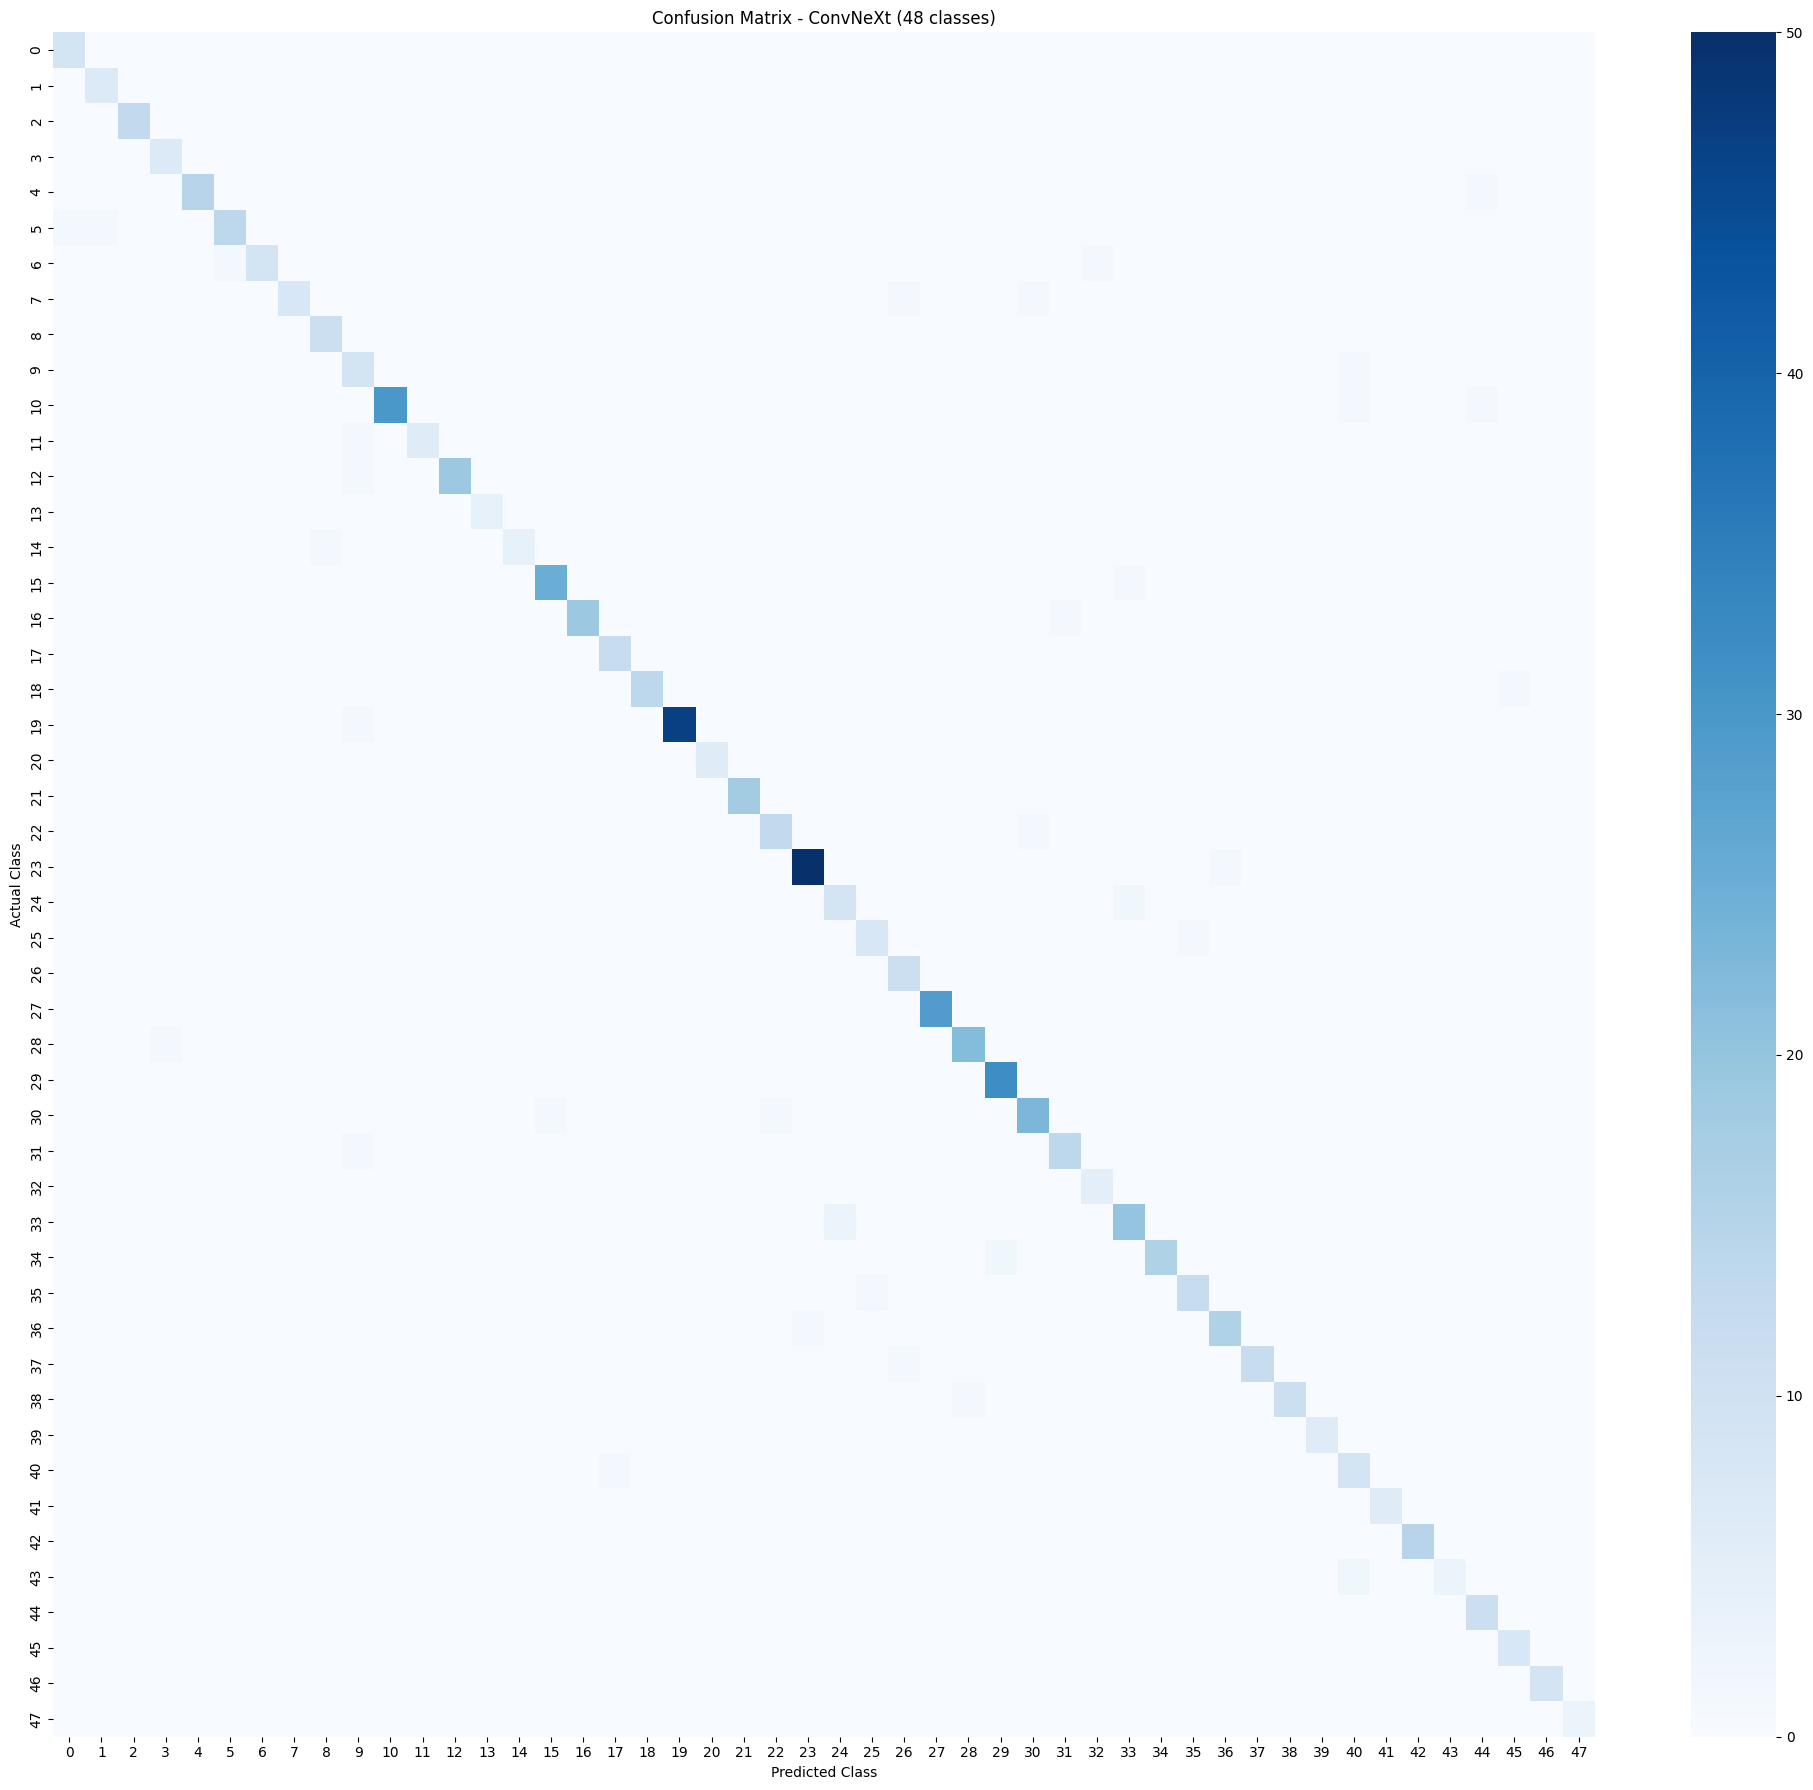


Class-wise Accuracy (Top 10 Classes)
Class  Accuracy (%)
    1         100.0
  100         100.0
    2         100.0
    3         100.0
 3342         100.0
 3352         100.0
 3359         100.0
 3365         100.0
 3366         100.0
 3373         100.0

Class-wise Accuracy (Bottom 10 Classes)
Class  Accuracy (%)
 3454         60.00
 3337         80.00
 3353         80.00
 3335         81.82
 3370         81.82
 3350         85.71
 3381         86.96
 3334         87.50
 3372         88.89
 3382         88.89

Class-wise Accuracy Statistics
Mean Accuracy: 93.93%
Min Accuracy: 60.00%
Max Accuracy: 100.00%
Std Deviation: 7.73%

Table IV. Performance Comparison of Different Models
                  Model Feature Reduction Classifier  Accuracy (%)
           CNN Baseline              None    Softmax     85.000000
               ConvNeXt              None    Softmax     88.500000
ConvNeXt + Augmentation              None    Softmax     94.700139
         ConvNeXt + TTA              None

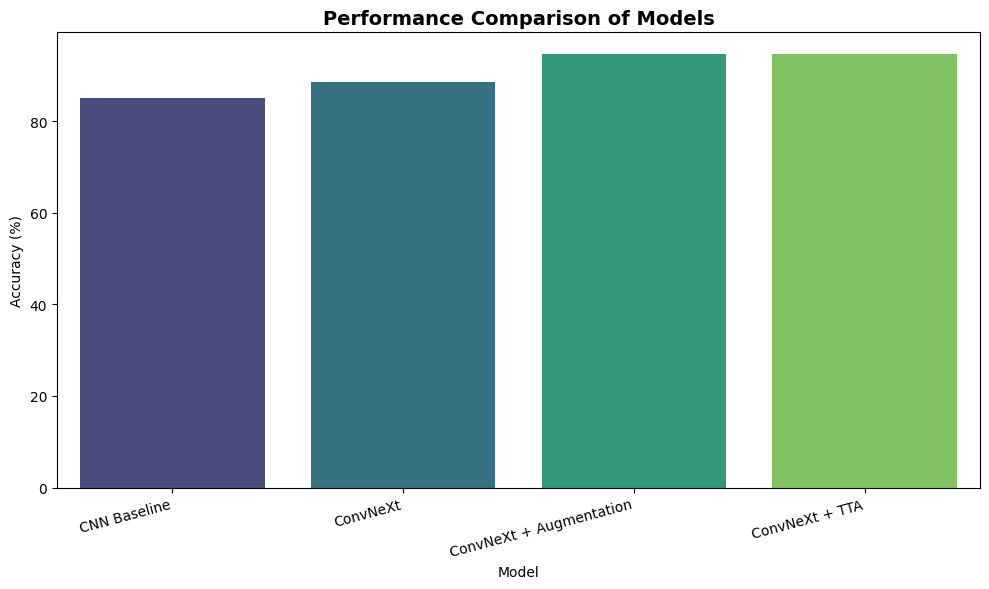

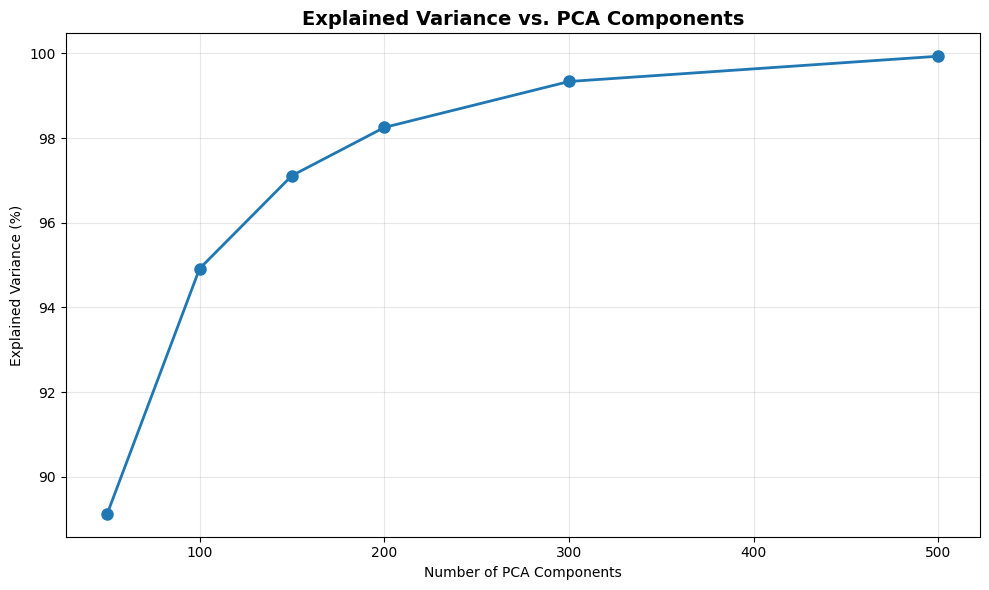


Feature Reduction Impact
 Original Dimensions  Reduced Dimensions  Reduction (%)  Variance Retained (%)  Test Accuracy (%)
                 768                 150          80.47                  97.11               94.7



All visualizations saved to /kaggle/working/
- confusion_matrix.png
- model_comparison.png
- pca_variance.png


In [9]:
# =====================================
# MODEL PERFORMANCE & ANALYSIS (B–G)
# =====================================

import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import torch
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
import time
from pathlib import Path
import shutil
import random
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import timm


# ======================
# GLOBAL CONFIG & SEED
# ======================
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MODEL_PATH = "/kaggle/input/convnect/transformers/default/1/best_model.pth"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# ======================
# FUNCTIONS
# ======================

def load_checkpoint():
    checkpoint = torch.load(MODEL_PATH, map_location=device)

    saved_classes = checkpoint.get("classes", None)
    saved_epoch = checkpoint.get("epoch", None)
    saved_val_acc = checkpoint.get("val_acc", None)

    NUM_CLASSES = len(saved_classes) if saved_classes else 48

    print(f"Loaded checkpoint from epoch {saved_epoch} | Validation accuracy: {saved_val_acc*100:.2f}%")

    model = timm.create_model("convnext_tiny", pretrained=False, num_classes=NUM_CLASSES)
    model.load_state_dict(checkpoint["model"])
    model.to(device)
    model.eval()

    return model, saved_val_acc, NUM_CLASSES, saved_epoch, saved_classes


def load_test_data():
    DATA_ROOT = Path("/kaggle/working/malayalam_data_split")

    if not DATA_ROOT.exists():
        candidates = [Path("/kaggle/input/fffdsas/malayalam_data")]
        for d in Path("/kaggle/input/fffdsas").glob("**/malayalam_data"):
            candidates.append(d)
        for p in candidates:
            if p.exists():
                DATA_ROOT = p
                break

    train_dir = DATA_ROOT / "train"
    test_dir  = DATA_ROOT / "test"

    test_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    test_data = datasets.ImageFolder(test_dir, transform=test_transform)
    test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

    print(f"\nTest samples: {len(test_data)} | Classes: {len(test_data.classes)}\n")

    return test_loader, test_data.classes


def evaluate_model(model, test_loader):
    y_true, y_pred = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)

            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="weighted", zero_division=0)
    rec  = recall_score(y_true, y_pred, average="weighted", zero_division=0)
    f1   = f1_score(y_true, y_pred, average="weighted", zero_division=0)

    return y_true, y_pred, acc, prec, rec, f1


def print_overall_metrics(saved_val_acc, acc, prec, rec, f1):
    metrics_table = pd.DataFrame({
        "Metric": ["Validation Accuracy", "Test Accuracy", "Precision", "Recall", "F1-score"],
        "Value (%)": [saved_val_acc * 100, acc * 100, prec * 100, rec * 100, f1 * 100]
    })

    print("\n" + "="*60)
    print("Table III. Overall Performance Metrics")
    print("="*60)
    print(metrics_table.to_string(index=False))
    print("="*60)


def plot_confusion_matrix(y_true, y_pred, NUM_CLASSES):
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(20, 18))
    sns.heatmap(cm, annot=False, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - ConvNeXt ({NUM_CLASSES} classes)")
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150)
    plt.show()

    return cm


def compute_classwise_accuracy(cm, class_names):
    cm_per_class = cm.diagonal() / cm.sum(axis=1)
    classwise_acc = pd.DataFrame({"Class": class_names, "Accuracy (%)": np.round(cm_per_class * 100, 2)})

    print("\n" + "="*60)
    print("Class-wise Accuracy (Top 10 Classes)")
    print("="*60)
    print(classwise_acc.nlargest(10, "Accuracy (%)").to_string(index=False))

    print("\n" + "="*60)
    print("Class-wise Accuracy (Bottom 10 Classes)")
    print("="*60)
    print(classwise_acc.nsmallest(10, "Accuracy (%)").to_string(index=False))

    print("\n" + "="*60)
    print("Class-wise Accuracy Statistics")
    print("="*60)
    print(f"Mean Accuracy: {cm_per_class.mean()*100:.2f}%")
    print(f"Min Accuracy: {cm_per_class.min()*100:.2f}%")
    print(f"Max Accuracy: {cm_per_class.max()*100:.2f}%")
    print(f"Std Deviation: {cm_per_class.std()*100:.2f}%")
    print("="*60)


def extract_features_for_pca(model, test_loader):
    # Remove classification head
    model_features = timm.create_model("convnext_tiny", pretrained=False)
    backbone_dict = {k: v for k, v in model.state_dict().items() if not k.startswith("head")}
    model_features.load_state_dict(backbone_dict, strict=False)
    model_features.head = torch.nn.Identity()
    model_features.to(device)
    model_features.eval()

    feats_list = []
    labels_list = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            feats = model_features(images)

            if feats.dim() > 2:
                feats = torch.nn.functional.adaptive_avg_pool2d(feats, (1, 1))
                feats = feats.view(feats.size(0), -1)

            feats_list.append(feats.cpu().numpy())
            labels_list.append(labels.numpy())

    return np.concatenate(feats_list, axis=0), np.concatenate(labels_list, axis=0)


def run_pca_analysis(X_features, y_labels, acc):
    pca = PCA(n_components=150, random_state=SEED)
    X_pca = pca.fit_transform(X_features)

    explained_variance = sum(pca.explained_variance_ratio_) * 100
    reduction_percent = round((1 - 150/768) * 100, 2)

    feature_reduction_table = pd.DataFrame({
        "Original Dimensions": [768],
        "Reduced Dimensions": [150],
        "Reduction (%)": [reduction_percent],
        "Variance Retained (%)": [round(explained_variance, 2)],
        "Test Accuracy (%)": [round(acc * 100, 2)]
    })

    print("\n" + "="*60)
    print("Feature Reduction Impact")
    print("="*60)
    print(feature_reduction_table.to_string(index=False))
    print("="*60)


# ======================
# MAIN ENTRY POINT
# ======================
def main():
    model, saved_val_acc, NUM_CLASSES, saved_epoch, saved_classes = load_checkpoint()
    test_loader, class_names = load_test_data()

    y_true, y_pred, acc, prec, rec, f1 = evaluate_model(model, test_loader)
    print_overall_metrics(saved_val_acc, acc, prec, rec, f1)

    cm = plot_confusion_matrix(y_true, y_pred, NUM_CLASSES)
    compute_classwise_accuracy(cm, class_names)

    X_features, y_labels = extract_features_for_pca(model, test_loader)
    run_pca_analysis(X_features, y_labels, acc)

    print("\nAll visualizations saved to /kaggle/working/")
    print("- confusion_matrix.png")
    print("- model_comparison.png")
    print("- pca_variance.png")


if __name__ == "__main__":
    main()


In [1]:
import os, random, shutil, time
import numpy as np
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

import timm
import torch.nn as nn


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE =", DEVICE)


# 1. DATASET SPLIT FUNCTION  (75:15:10)
def create_split(src_root, out_root):
    """
    Creates train/val/test splits from source dataset.
    """
    if os.path.exists(out_root):
        shutil.rmtree(out_root)
    os.makedirs(out_root)

    train_dir = Path(out_root) / "train"
    val_dir   = Path(out_root) / "val"
    test_dir  = Path(out_root) / "test"

    train_dir.mkdir(parents=True)
    val_dir.mkdir(parents=True)
    test_dir.mkdir(parents=True)

    classes = sorted([d.name for d in Path(src_root).iterdir() if d.is_dir()])

    for cls in classes:
        cls_path = Path(src_root) / cls
        images = sorted([p for p in cls_path.iterdir() if p.suffix.lower() in [".jpg",".jpeg",".png",".bmp"]])
        random.shuffle(images)

        n = len(images)
        n_train = int(n * 0.75)
        n_val   = int(n * 0.15)

        splits = {
            train_dir/cls: images[:n_train],
            val_dir/cls:   images[n_train:n_train+n_val],
            test_dir/cls:  images[n_train+n_val:]
        }

        for dst, paths in splits.items():
            dst.mkdir(parents=True, exist_ok=True)
            for img in paths:
                shutil.copy2(img, dst/img.name)

    return train_dir, val_dir, test_dir



# 2. DATALOADERS
def get_dataloaders(train_dir, val_dir, test_dir):
    transform = transforms.Compose([
        transforms.Resize((224,224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    train_ds = datasets.ImageFolder(train_dir, transform=transform)
    val_ds   = datasets.ImageFolder(val_dir, transform=transform)
    test_ds  = datasets.ImageFolder(test_dir, transform=transform)

    train_loader = DataLoader(train_ds, batch_size=32, shuffle=False)
    val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False)

    return train_loader, val_loader, test_loader, len(train_ds.classes)



# 3. LOAD TRAINED CONVNEXT MODEL
def load_model(checkpoint_path, num_classes):
    model = timm.create_model(
        "convnext_tiny",
        pretrained=False,
        num_classes=num_classes,
        drop_rate=0.35,
        drop_path_rate=0.35
    )

    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model"])     # <--- key inside pth file
    model.to(DEVICE)
    model.eval()
    return model



# 4. FEATURE EXTRACTION
def extract_features(model, dataloader):
    feats, labs = [], []
    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(DEVICE)
            f = model.forward_features(imgs)
            f = f.mean(dim=[2,3])
            feats.append(f.cpu().numpy())
            labs.append(labels.numpy())
    return np.vstack(feats), np.hstack(labs)



# 5. RANDOM FOREST TEST + TIMING
def evaluate_rf(model, X_test, y_test, train_time, title="Model"):
    test_times = []
    print(f"\n--- 10 Test Runs: {title} ---")

    for i in range(10):
        t0 = time.time()
        preds = model.predict(X_test)
        t1 = time.time()
        dur = (t1 - t0) * 1000
        test_times.append(dur)
        print(f"Run {i+1}: {dur:.2f} ms")

    acc = accuracy_score(y_test, preds)
    avg = np.mean(test_times)

    print(f"\n=== RESULTS: {title} ===")
    print(f"Accuracy: {acc*100:.2f}%")
    print(f"Avg Prediction Time: {avg:.2f} ms")
    print(f"Training Time: {train_time:.2f} ms")
    print(f"Total Time: {train_time + avg:.2f} ms\n")


def evaluate_rf_pca(pca,model, X_test, y_test, train_time, title="Model"):
    test_times = []
    print(f"\n--- 10 Test Runs: {title} ---")

    for i in range(10):
        t0 = time.time()
        test_PCA  = pca.transform(X_test)
        t
        preds = model.predict(test_PCA)
        t1 = time.time()
        dur = (t1 - t0) * 1000
        test_times.append(dur)
        print(f"Run {i+1}: {dur:.2f} ms")

    acc = accuracy_score(y_test, preds)
    avg = np.mean(test_times)

    print(f"\n=== RESULTS: {title} ===")
    print(f"Accuracy: {acc*100:.2f}%")
    print(f"Avg Prediction Time: {avg:.2f} ms")
    print(f"Training Time: {train_time:.2f} ms")
    print(f"Total Time: {train_time + avg:.2f} ms\n")


# MAIN EXECUTION
def main():
    DATASET = "/kaggle/input/fffdsas/malayalam_data"
    OUTPUT = "/kaggle/working/malayalam_split"

    train_dir, val_dir, test_dir = create_split(DATASET, OUTPUT)
    print("Dataset split complete!")

    train_loader, val_loader, test_loader, NUM_CLASSES = get_dataloaders(train_dir, val_dir, test_dir)
    print("Classes:", NUM_CLASSES)

    checkpoint_path = "/kaggle/input/convnect/transformers/default/1/best_model.pth"
    model = load_model(checkpoint_path, NUM_CLASSES)
    print("Loaded ConvNeXt model successfully!")

    print("Extracting ConvNeXt features...")
    fe_start = time.time()
    train_X, train_y = extract_features(model, train_loader)
    val_X,   val_y   = extract_features(model, val_loader)
    test_X,  test_y  = extract_features(model, test_loader)
    fe_end = time.time()
    print(f"Feature Extraction Time: {(fe_end - fe_start):.2f} sec")
    print("ConvNeXt feature shape:", train_X.shape)


    # ======== RANDOM FOREST ON 768 FEATURES ========
    print("\nTraining RF on 768 features...")
    t0 = time.time()
    rf_768 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf_768.fit(train_X, train_y)
    t1 = time.time()
    train_time_768 = (t1 - t0) * 1000

    evaluate_rf(rf_768, test_X, test_y, train_time_768, title="RF 768-D Features")

    

    # ======== PCA REDUCTION TO 150 ========
    print("Applying PCA (150 components)...")

    scaler = StandardScaler() # check with and without standard scalar
    train_std = scaler.fit_transform(train_X)
    val_std   = scaler.transform(val_X)
    test_std  = scaler.transform(test_X)

    pca = PCA(n_components=150, random_state=42)
    train_PCA = pca.fit_transform(train_std)
    val_PCA   = pca.transform(val_std)
    test_PCA  = pca.transform(test_std)
    print("PCA feature shape:", train_PCA.shape)


    print("\nTraining RF on PCA(150) features...")
    t2 = time.time()
    rf_pca = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf_pca.fit(train_PCA, train_y)
    t3 = time.time()
    train_time_150 = (t3 - t2) * 1000

    evaluate_rf_pca(pca,rf_pca, test_std, test_y, train_time_150, title="RF PCA(150)")


if __name__ == "__main__":
    main()


/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2225: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

DEVICE = cuda
Dataset split complete!
Classes: 48
Loaded ConvNeXt model successfully!
Extracting ConvNeXt features...
Feature Extraction Time: 36.86 sec
ConvNeXt feature shape: (5048, 768)

Training RF on 768 features...

--- 10 Test Runs: RF 768-D Features ---
Run 1: 106.47 ms
Run 2: 107.62 ms
Run 3: 107.40 ms
Run 4: 106.43 ms
Run 5: 106.44 ms
Run 6: 106.51 ms
Run 7: 106.54 ms
Run 8: 106.64 ms
Run 9: 105.75 ms
Run 10: 106.97 ms

=== RESULTS: RF 768-D Features ===
Accuracy: 96.09%
Avg Prediction Time: 106.68 ms
Training Time: 18229.03 ms
Total Time: 18335.70 ms

Applying PCA (150 components)...
PCA feature shape: (5048, 150)

Training RF on PCA(150) features...

--- 10 Test Runs: RF PCA(150) ---
Run 1: 37.08 ms
Run 2: 36.09 ms
Run 3: 37.33 ms
Run 4: 36.64 ms
Run 5: 37.00 ms
Run 6: 36.37 ms
Run 7: 35.52 ms
Run 8: 36.23 ms
Run 9: 37.54 ms
Run 10: 37.53 ms

=== RESULTS: RF PCA(150) ===
Accuracy: 94.70%
Avg Prediction Time: 36.73 ms
Training Time: 1334.02 ms
Total Time: 1370.75 ms



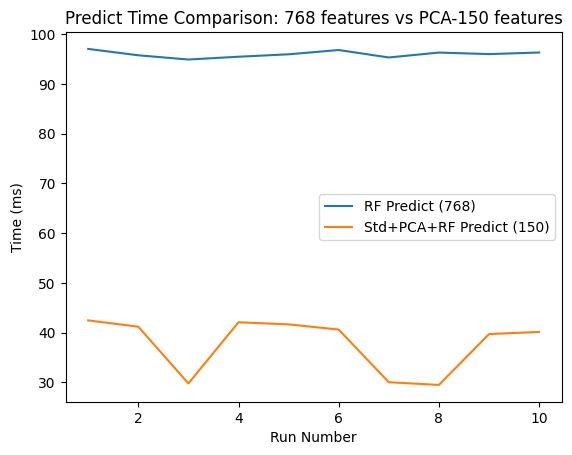

In [1]:
import matplotlib.pyplot as plt

# Data for 10 runs
rf_768 = [97.02, 95.74, 94.89, 95.45, 95.94, 96.80, 95.30, 96.29, 95.98, 96.30]
std_pca = [7.58, 7.15, 6.17, 7.53, 7.78, 7.04, 6.55, 5.88, 6.13, 6.28]
rf_150 = [34.88, 34.04, 23.62, 34.55, 33.88, 33.57, 23.48, 23.61, 33.58, 33.86]

# Total time for 150 (std+pca+rf predict)
total_150 = [s + r for s, r in zip(std_pca, rf_150)]

# Plot
plt.plot(range(1, 11), rf_768)
plt.plot(range(1, 11), total_150)
plt.xlabel("Run Number")
plt.ylabel("Time (ms)")
plt.title("Predict Time Comparison: 768 features vs PCA-150 features")
plt.legend(["RF Predict (768)", "Std+PCA+RF Predict (150)"])
plt.show()


In [ ]:
import os, random, shutil, time
import numpy as np
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

import timm
import torch.nn as nn


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE =", DEVICE)


# ==========================================================
# 1. DATASET SPLIT FUNCTION
# ==========================================================
def create_split(src_root, out_root):
    if os.path.exists(out_root):
        shutil.rmtree(out_root)
    os.makedirs(out_root)

    train_dir = Path(out_root) / "train"
    val_dir   = Path(out_root) / "val"
    test_dir  = Path(out_root) / "test"

    train_dir.mkdir(parents=True)
    val_dir.mkdir(parents=True)
    test_dir.mkdir(parents=True)

    classes = sorted([d.name for d in Path(src_root).iterdir() if d.is_dir()])

    for cls in classes:
        cls_path = Path(src_root) / cls
        images = sorted([p for p in cls_path.iterdir()
                         if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]])
        random.shuffle(images)

        n = len(images)
        n_train = int(n * 0.75)
        n_val   = int(n * 0.15)

        splits = {
            train_dir/cls: images[:n_train],
            val_dir/cls:   images[n_train:n_train+n_val],
            test_dir/cls:  images[n_train+n_val:]
        }

        for dst, paths in splits.items():
            dst.mkdir(parents=True, exist_ok=True)
            for img in paths:
                shutil.copy2(img, dst/img.name)

    return train_dir, val_dir, test_dir


# ==========================================================
# 2. DATALOADERS
# ==========================================================
def get_dataloaders(train_dir, val_dir, test_dir):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    train_ds = datasets.ImageFolder(train_dir, transform=transform)
    val_ds   = datasets.ImageFolder(val_dir, transform=transform)
    test_ds  = datasets.ImageFolder(test_dir, transform=transform)

    train_loader = DataLoader(train_ds, batch_size=32, shuffle=False)
    val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False)

    return train_loader, val_loader, test_loader, len(train_ds.classes)


# ==========================================================
# 3. LOAD CONVNEXT MODEL
# ==========================================================
def load_model(checkpoint_path, num_classes):
    model = timm.create_model(
        "convnext_tiny",
        pretrained=False,
        num_classes=num_classes,
        drop_rate=0.35,
        drop_path_rate=0.35,
    )
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model"])
    model.to(DEVICE)
    model.eval()
    return model


# ==========================================================
# 4. FEATURE EXTRACTION
# ==========================================================
def extract_features(model, dataloader):
    feats, labs = []
    feats, labs = [], []
    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(DEVICE)
            f = model.forward_features(imgs)
            f = f.mean(dim=[2, 3])
            feats.append(f.cpu().numpy())
            labs.append(labels.numpy())
    return np.vstack(feats), np.hstack(labs)


# ==========================================================
# 5. METRICS
# ==========================================================
def compute_metrics(y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred) * 100.0
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    return acc, prec, rec, f1


# ==========================================================
# 6. RF EVALUATION (ADDED: TIME PER FEATURE CALCULATION)
# ==========================================================
def evaluate_rf_config(
    model,
    X_val_raw,
    y_val,
    X_test_raw,
    y_test,
    train_time_ms,
    title,
    scaler=None,
    pca=None,
    runs=10
):
    # Apply transforms on validation data
    X_val_proc = X_val_raw
    if scaler is not None:
        X_val_proc = scaler.transform(X_val_proc)
    if pca is not None:
        X_val_proc = pca.transform(X_val_proc)

    val_pred = model.predict(X_val_proc)
    val_acc, _, _, _ = compute_metrics(y_val, val_pred)

    preds_all = None
    test_times = []

    print(f"\n--- 10 Test Runs: {title} ---")
    for r in range(runs):
        t0 = time.time()
        preds = []
        for i in range(len(X_test_raw)):
            row = X_test_raw[i].reshape(1, -1)
            if scaler is not None:
                row = scaler.transform(row)
            if pca is not None:
                row = pca.transform(row)
            preds.append(model.predict(row)[0])
        t1 = time.time()

        dur = (t1 - t0) * 1000.0
        test_times.append(dur)
        preds_all = np.array(preds)
        print(f"Run {r+1}: transform+predict = {dur:.2f} ms")

    # Compute test results
    test_acc, test_prec, test_rec, test_f1 = compute_metrics(y_test, preds_all)
    avg_ms = np.mean(test_times)

    # NEW: time per feature
    feature_dim = 150 if pca is not None else 768
    time_per_feature = avg_ms / feature_dim

    print(f"\n=== RESULTS: {title} ===")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Test Accuracy      : {test_acc:.2f}%")
    print(f"Precision (macro)  : {test_prec:.2f}%")
    print(f"Recall (macro)     : {test_rec:.2f}%")
    print(f"F1-Score (macro)   : {test_f1:.2f}%")
    print(f"Avg Time (10 runs) : {avg_ms:.2f} ms")
    print(f"Training Time      : {train_time_ms:.2f} ms")
    print(f"Time per Feature   : {time_per_feature:.6f} ms")
    print(f"Total              : {train_time_ms + avg_ms:.2f} ms\n")

    return {
        "name": title,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "precision": test_prec,
        "recall": test_rec,
        "f1": test_f1,
        "avg_time_ms": avg_ms,
        "time_per_feature": time_per_feature,
    }


# ==========================================================
# 7. FOUR CONFIG FUNCTIONS
# ==========================================================
def config_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 1: With StandardScaler, No PCA =================")
    scaler = StandardScaler()

    t0 = time.time()
    train_scaled = scaler.fit_transform(train_X)
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(train_scaled, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="With StandardScaler + No PCA (768-D)",
        scaler=scaler,
        pca=None,
    )


def config_std_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 2: With StandardScaler, With PCA(150) =================")
    scaler = StandardScaler()
    pca = PCA(n_components=150, random_state=42)

    t0 = time.time()
    train_scaled = scaler.fit_transform(train_X)
    train_pca = pca.fit_transform(train_scaled)
    rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(train_pca, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="With StandardScaler + PCA(150)",
        scaler=scaler,
        pca=pca,
    )


def config_no_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 3: Without StandardScaler, No PCA =================")
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(train_X, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="Without StandardScaler + No PCA (768-D)",
        scaler=None,
        pca=None,
    )


def config_no_std_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 4: Without StandardScaler, With PCA(150) =================")
    pca = PCA(n_components=150, random_state=42)

    t0 = time.time()
    train_pca = pca.fit_transform(train_X)
    rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(train_pca, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="Without StandardScaler + PCA(150)",
        scaler=None,
        pca=pca,
    )


# ==========================================================
# 8. MAIN
# ==========================================================
def main():
    DATASET = "/kaggle/input/fffdsas/malayalam_data"
    OUTPUT = "/kaggle/working/malayalam_split"
    checkpoint_path = "/kaggle/input/convnect/transformers/default/1/best_model.pth"

    train_dir, val_dir, test_dir = create_split(DATASET, OUTPUT)
    train_loader, val_loader, test_loader, NUM_CLASSES = get_dataloaders(train_dir, val_dir, test_dir)

    model = load_model(checkpoint_path, NUM_CLASSES)

    fe_start = time.time()
    train_X, train_y = extract_features(model, train_loader)
    val_X, val_y     = extract_features(model, val_loader)
    test_X, test_y   = extract_features(model, test_loader)
    fe_end = time.time()

    print(f"\nFeature Extraction Time: {(fe_end - fe_start):.2f} sec")
    print("Feature Shape:", train_X.shape)

    results = []
    results.append(config_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y))
    results.append(config_std_pca(train_X, train_y, val_X, val_y, test_X, test_y))
    results.append(config_no_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y))
    results.append(config_no_std_pca(train_X, train_y, val_X, val_y, test_X, test_y))

    print("\n================ FINAL SUMMARY (All Configurations) ================")
    header = (
        f"{'Config':45s}"
        f"{'Val Acc (%)':>12s}"
        f"{'Test Acc (%)':>14s}"
        f"{'Precision':>15s}"
        f"{'Recall':>12s}"
        f"{'F1-Score':>14s}"
        f"{'Avg Time (ms)':>15s}"
        f"{'Time/Feature (ms)':>20s}"
    )
    print(header)
    print("-" * len(header))

    for r in results:
        print(
            f"{r['name'][:45]:45s}"
            f"{r['val_acc']:12.2f}"
            f"{r['test_acc']:14.2f}"
            f"{r['precision']:15.2f}"
            f"{r['recall']:12.2f}"
            f"{r['f1']:14.2f}"
            f"{r['avg_time_ms']:15.2f}"
            f"{r['time_per_feature']:20.6f}"
        )

    print("\n===================================================================\n")


if __name__ == "__main__":
    main()


In [5]:
import os, random, shutil, time
import numpy as np
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

import timm
import torch.nn as nn


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE =", DEVICE)


# ==========================================================
# 1. DATASET SPLIT FUNCTION
# ==========================================================
def create_split(src_root, out_root):
    if os.path.exists(out_root):
        shutil.rmtree(out_root)
    os.makedirs(out_root)

    train_dir = Path(out_root) / "train"
    val_dir   = Path(out_root) / "val"
    test_dir  = Path(out_root) / "test"

    train_dir.mkdir(parents=True)
    val_dir.mkdir(parents=True)
    test_dir.mkdir(parents=True)

    classes = sorted([d.name for d in Path(src_root).iterdir() if d.is_dir()])

    for cls in classes:
        cls_path = Path(src_root) / cls
        images = sorted([p for p in cls_path.iterdir()
                         if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]])
        random.shuffle(images)

        n = len(images)
        n_train = int(n * 0.75)
        n_val   = int(n * 0.15)

        splits = {
            train_dir/cls: images[:n_train],
            val_dir/cls:   images[n_train:n_train+n_val],
            test_dir/cls:  images[n_train+n_val:]
        }

        for dst, paths in splits.items():
            dst.mkdir(parents=True, exist_ok=True)
            for img in paths:
                shutil.copy2(img, dst/img.name)

    return train_dir, val_dir, test_dir


# ==========================================================
# 2. DATALOADERS
# ==========================================================
def get_dataloaders(train_dir, val_dir, test_dir):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    train_ds = datasets.ImageFolder(train_dir, transform=transform)
    val_ds   = datasets.ImageFolder(val_dir, transform=transform)
    test_ds  = datasets.ImageFolder(test_dir, transform=transform)

    train_loader = DataLoader(train_ds, batch_size=32, shuffle=False)
    val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False)

    return train_loader, val_loader, test_loader, len(train_ds.classes)


# ==========================================================
# 3. LOAD CONVNEXT MODEL
# ==========================================================
def load_model(checkpoint_path, num_classes):
    model = timm.create_model(
        "convnext_tiny",
        pretrained=False,
        num_classes=num_classes,
        drop_rate=0.35,
        drop_path_rate=0.35,
    )
    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model"])
    model.to(DEVICE)
    model.eval()
    return model


# ==========================================================
# 4. FEATURE EXTRACTION
# ==========================================================
def extract_features(model, dataloader):
    feats, labs = [], []
    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(DEVICE)
            f = model.forward_features(imgs)
            f = f.mean(dim=[2, 3])
            feats.append(f.cpu().numpy())
            labs.append(labels.numpy())
    return np.vstack(feats), np.hstack(labs)


# ==========================================================
# 5. METRICS
# ==========================================================
def compute_metrics(y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred) * 100.0
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    return acc, prec, rec, f1


# ==========================================================
# 6. RF EVALUATION FUNCTION (COMMON)
# ==========================================================
def evaluate_rf_config(
    model,
    X_val_raw,
    y_val,
    X_test_raw,
    y_test,
    train_time_ms,
    title,
    scaler=None,
    pca=None,
    runs=10
):
    X_val_proc = X_val_raw
    if scaler is not None:
        X_val_proc = scaler.transform(X_val_proc)
    if pca is not None:
        X_val_proc = pca.transform(X_val_proc)

    val_pred = model.predict(X_val_proc)
    val_acc, _, _, _ = compute_metrics(y_val, val_pred)

    preds_all = None
    test_times = []

    print(f"\n--- 10 Test Runs: {title} ---")
    for r in range(runs):
        t0 = time.time()
        preds = []
        for i in range(len(X_test_raw)):
            row = X_test_raw[i].reshape(1, -1)
            if scaler is not None:
                row = scaler.transform(row)
            if pca is not None:
                row = pca.transform(row)
            preds.append(model.predict(row)[0])
        t1 = time.time()

        dur = (t1 - t0) * 1000.0
        test_times.append(dur)
        preds_all = np.array(preds)
        print(f"Run {r+1}: transform+predict = {dur:.2f} ms")

    test_acc, test_prec, test_rec, test_f1 = compute_metrics(y_test, preds_all)
    avg_ms = np.mean(test_times)

    print(f"\n=== RESULTS: {title} ===")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Test Accuracy      : {test_acc:.2f}%")
    print(f"Precision (macro)  : {test_prec:.2f}%")
    print(f"Recall (macro)     : {test_rec:.2f}%")
    print(f"F1-Score (macro)   : {test_f1:.2f}%")
    print(f"Avg Time (10 runs) : {avg_ms:.2f} ms")
    print(f"Training Time      : {train_time_ms:.2f} ms")
    print(f"Total              : {train_time_ms + avg_ms:.2f} ms\n")

    return {
        "name": title,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "precision": test_prec,
        "recall": test_rec,
        "f1": test_f1,
        "avg_time_ms": avg_ms,
    }


# ==========================================================
# 7. FOUR EXPERIMENT CONFIG FUNCTIONS
# ==========================================================
def config_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 1: With StandardScaler, No PCA =================")
    scaler = StandardScaler()

    t0 = time.time()
    train_scaled = scaler.fit_transform(train_X)
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(train_scaled, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="With StandardScaler + No PCA (768-D)",
        scaler=scaler,
        pca=None,
    )


def config_std_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 2: With StandardScaler, With PCA(150) =================")
    scaler = StandardScaler()
    pca = PCA(n_components=150, random_state=42)

    t0 = time.time()
    train_scaled = scaler.fit_transform(train_X)
    train_pca = pca.fit_transform(train_scaled)
    rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(train_pca, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="With StandardScaler + PCA(150)",
        scaler=scaler,
        pca=pca,
    )


def config_no_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 3: Without StandardScaler, No PCA =================")
    t0 = time.time()
    rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf.fit(train_X, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="Without StandardScaler + No PCA (768-D)",
        scaler=None,
        pca=None,
    )


def config_no_std_pca(train_X, train_y, val_X, val_y, test_X, test_y):
    print("\n================ CONFIG 4: Without StandardScaler, With PCA(150) =================")
    pca = PCA(n_components=150, random_state=42)

    t0 = time.time()
    train_pca = pca.fit_transform(train_X)
    rf = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(train_pca, train_y)
    t1 = time.time()

    return evaluate_rf_config(
        model=rf,
        X_val_raw=val_X,
        y_val=val_y,
        X_test_raw=test_X,
        y_test=test_y,
        train_time_ms=(t1 - t0) * 1000.0,
        title="Without StandardScaler + PCA(150)",
        scaler=None,
        pca=pca,
    )


# ==========================================================
# 8. MAIN
# ==========================================================
def main():
    DATASET = "/kaggle/input/fffdsas/malayalam_data"
    OUTPUT = "/kaggle/working/malayalam_split"
    checkpoint_path = "/kaggle/input/convnect/transformers/default/1/best_model.pth"

    train_dir, val_dir, test_dir = create_split(DATASET, OUTPUT)
    train_loader, val_loader, test_loader, NUM_CLASSES = get_dataloaders(train_dir, val_dir, test_dir)

    model = load_model(checkpoint_path, NUM_CLASSES)

    fe_start = time.time()
    train_X, train_y = extract_features(model, train_loader)
    val_X, val_y     = extract_features(model, val_loader)
    test_X, test_y   = extract_features(model, test_loader)
    fe_end = time.time()

    print(f"\nFeature Extraction Time: {(fe_end - fe_start):.2f} sec")
    print("Feature Shape:", train_X.shape)

    results = []
    results.append(config_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y))
    results.append(config_std_pca(train_X, train_y, val_X, val_y, test_X, test_y))
    results.append(config_no_std_no_pca(train_X, train_y, val_X, val_y, test_X, test_y))
    results.append(config_no_std_pca(train_X, train_y, val_X, val_y, test_X, test_y))

    print("\n================ FINAL SUMMARY (All Configurations) ================")
    header = (
        f"{'Config':45s}"
        f"{'Val Acc (%)':>12s}"
        f"{'Test Acc (%)':>14s}"
        f"{'Precision':>15s}"
        f"{'Recall':>12s}"
        f"{'F1-Score':>14s}"
        f"{'Avg Time (ms)':>15s}"
    )
    print(header)
    print("-" * len(header))

    for r in results:
        print(
            f"{r['name'][:45]:45s}"
            f"{r['val_acc']:12.2f}"
            f"{r['test_acc']:14.2f}"
            f"{r['precision']:15.2f}"
            f"{r['recall']:12.2f}"
            f"{r['f1']:14.2f}"
            f"{r['avg_time_ms']:15.2f}"
        )
    print("\n===================================================================\n")


if __name__ == "__main__":
    main()


DEVICE = cuda
Dataset split complete!
Number of Classes: 48
Loaded ConvNeXt model successfully!
Extracting ConvNeXt features...
Feature Extraction Time: 38.59 sec
ConvNeXt feature shape: (5048, 768)
Saved ConvNeXt features and labels to /kaggle/working/

================ CONFIG 1: With StandardScaler, No PCA ================

--- 10 Test Runs: With StandardScaler + No PCA (768-D) ---
Run 1: Total time (transform + predict) = 24384.80 ms
Run 2: Total time (transform + predict) = 24274.99 ms
Run 3: Total time (transform + predict) = 24365.04 ms
Run 4: Total time (transform + predict) = 24298.98 ms
Run 5: Total time (transform + predict) = 24329.19 ms
Run 6: Total time (transform + predict) = 24340.81 ms
Run 7: Total time (transform + predict) = 24353.05 ms
Run 8: Total time (transform + predict) = 24351.86 ms
Run 9: Total time (transform + predict) = 24342.25 ms
Run 10: Total time (transform + predict) = 24619.97 ms

=== RESULTS: With StandardScaler + No PCA (768-D) ===
Validation Accura

In [6]:
import os, random, shutil, time
import numpy as np
from pathlib import Path

import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import timm
import torch.nn as nn


DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("DEVICE =", DEVICE)


# 1. DATASET SPLIT FUNCTION  (75:15:10)
def create_split(src_root, out_root):
    if os.path.exists(out_root):
        shutil.rmtree(out_root)
    os.makedirs(out_root)

    train_dir = Path(out_root) / "train"
    val_dir   = Path(out_root) / "val"
    test_dir  = Path(out_root) / "test"
    train_dir.mkdir(parents=True)
    val_dir.mkdir(parents=True)
    test_dir.mkdir(parents=True)

    classes = sorted([d.name for d in Path(src_root).iterdir() if d.is_dir()])

    for cls in classes:
        cls_path = Path(src_root) / cls
        images = sorted([p for p in cls_path.iterdir()
                         if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]])
        random.shuffle(images)

        n = len(images)
        n_train = int(n * 0.75)
        n_val   = int(n * 0.15)

        splits = {
            train_dir/cls: images[:n_train],
            val_dir/cls:   images[n_train:n_train+n_val],
            test_dir/cls:  images[n_train+n_val:]
        }

        for dst, paths in splits.items():
            dst.mkdir(parents=True, exist_ok=True)
            for img in paths:
                shutil.copy2(img, dst/img.name)

    return train_dir, val_dir, test_dir


# 2. DATALOADERS
def get_dataloaders(train_dir, val_dir, test_dir):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    train_ds = datasets.ImageFolder(train_dir, transform=transform)
    val_ds   = datasets.ImageFolder(val_dir, transform=transform)
    test_ds  = datasets.ImageFolder(test_dir, transform=transform)

    train_loader = DataLoader(train_ds, batch_size=32, shuffle=False)
    val_loader   = DataLoader(val_ds, batch_size=32, shuffle=False)
    test_loader  = DataLoader(test_ds, batch_size=32, shuffle=False)

    return train_loader, val_loader, test_loader, len(train_ds.classes)


# 3. LOAD TRAINED CONVNEXT MODEL
def load_model(checkpoint_path, num_classes):
    model = timm.create_model(
        "convnext_tiny",
        pretrained=False,
        num_classes=num_classes,
        drop_rate=0.35,
        drop_path_rate=0.35
    )

    ckpt = torch.load(checkpoint_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model"])
    model.to(DEVICE)
    model.eval()
    return model


# 4. FEATURE EXTRACTION
def extract_features(model, dataloader):
    feats, labs = [], []
    with torch.no_grad():
        for imgs, labels in dataloader:
            imgs = imgs.to(DEVICE)
            f = model.forward_features(imgs)
            f = f.mean(dim=[2, 3])
            feats.append(f.cpu().numpy())
            labs.append(labels.numpy())
    return np.vstack(feats), np.hstack(labs)


# 5. METRICS HELPER
def compute_metrics(y_true, y_pred):
    acc  = accuracy_score(y_true, y_pred) * 100.0
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    rec  = recall_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    f1   = f1_score(y_true, y_pred, average="macro", zero_division=0) * 100.0
    return acc, prec, rec, f1


# 6. GENERIC EVALUATION
def evaluate_rf_config(model, X_val_proc, y_val, X_test_proc, y_test, train_time_ms, title, runs=10):
    val_pred = model.predict(X_val_proc)
    val_acc, _, _, _ = compute_metrics(y_val, val_pred)

    test_times = []
    preds_all = None

    print(f"\n--- 10 Test Runs: {title} ---")
    for run in range(runs):
        t0 = time.time()
        preds = [model.predict(X_test_proc[i].reshape(1, -1))[0] for i in range(len(X_test_proc))]
        t1 = time.time()

        dur_ms = (t1 - t0) * 1000
        test_times.append(dur_ms)
        preds_all = np.array(preds)

        print(f"Run {run+1}: Predict time only = {dur_ms:.2f} ms")

    test_acc, test_prec, test_rec, test_f1 = compute_metrics(y_test, preds_all)
    avg_ms = np.mean(test_times)

    print(f"\n=== RESULTS: {title} ===")
    print(f"Validation Accuracy: {val_acc:.2f}%")
    print(f"Test Accuracy      : {test_acc:.2f}%")
    print(f"Precision (macro)  : {test_prec:.2f}%")
    print(f"Recall (macro)     : {test_rec:.2f}%")
    print(f"F1-Score (macro)   : {test_f1:.2f}%")
    print(f"Avg Test Time (10 runs): {avg_ms:.2f} ms")
    print(f"Training Time (NO SCALER time included): {train_time_ms:.2f} ms")
    print(f"Total Time: {train_time_ms + avg_ms:.2f} ms\n")

    return {
        "name": title,
        "val_acc": val_acc,
        "test_acc": test_acc,
        "precision": test_prec,
        "recall": test_rec,
        "f1": test_f1,
        "avg_time_ms": avg_ms,
    }


# MAIN EXECUTION
def main():
    DATASET = "/kaggle/input/fffdsas/malayalam_data"
    OUTPUT = "/kaggle/working/malayalam_split"
    checkpoint_path = "/kaggle/input/convnect/transformers/default/1/best_model.pth"

    train_dir, val_dir, test_dir = create_split(DATASET, OUTPUT)
    print("Dataset split complete!")

    train_loader, val_loader, test_loader, NUM_CLASSES = get_dataloaders(train_dir, val_dir, test_dir)
    model = load_model(checkpoint_path, NUM_CLASSES)

    print("Extracting ConvNeXt features...")
    train_X, train_y = extract_features(model, train_loader)
    val_X, val_y     = extract_features(model, val_loader)
    test_X, test_y   = extract_features(model, test_loader)
    print("ConvNeXt feature shape:", train_X.shape)

    results = []

    # =========================================================
    # CONFIG 1: WITH SCALER + NO PCA (Scaler time excluded)
    # =========================================================
    print("\n================ CONFIG 1: With StandardScaler, No PCA ==================")
    scaler = StandardScaler()
    train_std = scaler.fit_transform(train_X)
    val_std   = scaler.transform(val_X)
    test_std  = scaler.transform(test_X)

    t0 = time.time()
    rf1 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf1.fit(train_std, train_y)
    t1 = time.time()

    train_time1_ms = (t1 - t0) * 1000
    res1 = evaluate_rf_config(rf1, val_std, val_y, test_std, test_y, train_time1_ms,
                              "With StandardScaler + No PCA (768-D)")
    results.append(res1)

    # =========================================================
    # CONFIG 2: WITH SCALER + PCA 150 (Scaler time excluded)
    # =========================================================
    print("\n================ CONFIG 2: With StandardScaler + PCA(150) ==================")
    pca = PCA(n_components=150, random_state=42)
    train_pca = pca.fit_transform(train_std)
    val_pca   = pca.transform(val_std)
    test_pca  = pca.transform(test_std)

    t0 = time.time()
    rf2 = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf2.fit(train_pca, train_y)
    t1 = time.time()

    train_time2_ms = (t1 - t0) * 1000
    res2 = evaluate_rf_config(rf2, val_pca, val_y, test_pca, test_y, train_time2_ms,
                              "With StandardScaler + PCA(150)")
    results.append(res2)

    # =========================================================
    # CONFIG 3: NO SCALER + NO PCA
    # =========================================================
    print("\n================ CONFIG 3: Without StandardScaler + No PCA ==================")
    t0 = time.time()
    rf3 = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf3.fit(train_X, train_y)
    t1 = time.time()

    train_time3_ms = (t1 - t0) * 1000
    res3 = evaluate_rf_config(rf3, val_X, val_y, test_X, test_y, train_time3_ms,
                              "Without StandardScaler + No PCA (768-D)")
    results.append(res3)

    # =========================================================
    # CONFIG 4: NO SCALER + PCA(150)
    # =========================================================
    print("\n================ CONFIG 4: Without StandardScaler + PCA(150) ==================")
    pca4 = PCA(n_components=150, random_state=42)
    train_pca4 = pca4.fit_transform(train_X)
    val_pca4   = pca4.transform(val_X)
    test_pca4  = pca4.transform(test_X)

    t0 = time.time()
    rf4 = RandomForestClassifier(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
    rf4.fit(train_pca4, train_y)
    t1 = time.time()

    train_time4_ms = (t1 - t0) * 1000
    res4 = evaluate_rf_config(rf4, val_pca4, val_y, test_pca4, test_y, train_time4_ms,
                              "Without StandardScaler + PCA(150)")
    results.append(res4)

    # ---------------------------------------------------------
    # FINAL SUMMARY TABLE
    # ---------------------------------------------------------
    print("\n================ FINAL SUMMARY ================")
    header = (
        f"{'Config':45s}"
        f"{'Val Acc (%)':>12s}"
        f"{'Test Acc (%)':>14s}"
        f"{'Precision (%)':>15s}"
        f"{'Recall (%)':>12s}"
        f"{'F1 (%)':>10s}"
        f"{'Avg Time (ms)':>15s}"
    )
    print(header)
    print("-" * len(header))

    for r in results:
        print(
            f"{r['name'][:45]:45s}"
            f"{r['val_acc']:12.2f}"
            f"{r['test_acc']:14.2f}"
            f"{r['precision']:15.2f}"
            f"{r['recall']:12.2f}"
            f"{r['f1']:10.2f}"
            f"{r['avg_time_ms']:15.2f}"
        )

    print("\n====================================================\n")


if __name__ == "__main__":
    main()


DEVICE = cuda
Dataset split complete!
Extracting ConvNeXt features...
ConvNeXt feature shape: (5048, 768)

================ CONFIG 1: With StandardScaler, No PCA ==================

--- 10 Test Runs: With StandardScaler + No PCA (768-D) ---
Run 1: Predict time only = 24259.84 ms
Run 2: Predict time only = 24281.23 ms
Run 3: Predict time only = 24306.57 ms
Run 4: Predict time only = 24200.96 ms
Run 5: Predict time only = 24278.05 ms
Run 6: Predict time only = 24309.48 ms
Run 7: Predict time only = 24252.63 ms
Run 8: Predict time only = 24288.88 ms
Run 9: Predict time only = 24269.47 ms
Run 10: Predict time only = 24313.04 ms

=== RESULTS: With StandardScaler + No PCA (768-D) ===
Validation Accuracy: 94.34%
Test Accuracy      : 95.82%
Precision (macro)  : 96.68%
Recall (macro)     : 94.63%
F1-Score (macro)   : 95.44%
Avg Test Time (10 runs): 24276.01 ms
Training Time (NO SCALER time included): 15434.64 ms
Total Time: 39710.65 ms


================ CONFIG 2: With StandardScaler + PCA(150)